In [10]:
!pip -q install -U autogluon.tabular sentence-transformers shap

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


In [11]:
import pandas as pd
import numpy as np
import ast
import re
import warnings

warnings.filterwarnings("ignore")

# Upload CSV if it is not already present
from google.colab import files
import os

FILE = "/content/resume_data_for_ranking.csv"

if not os.path.exists(FILE):
    uploaded = files.upload()
    FILE = "/content/" + list(uploaded.keys())[0]

df = pd.read_csv(FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (9544, 35)

Columns:
['address', 'career_objective', 'skills', 'educational_institution_name', 'degree_names', 'passing_years', 'educational_results', 'result_types', 'major_field_of_studies', 'professional_company_names', 'company_urls', 'start_dates', 'end_dates', 'related_skils_in_job', 'positions', 'locations', 'responsibilities', 'extra_curricular_activity_types', 'extra_curricular_organization_names', 'extra_curricular_organization_links', 'role_positions', 'languages', 'proficiency_levels', 'certification_providers', 'certification_skills', 'online_links', 'issue_dates', 'expiry_dates', 'job_position_name', 'educationaL_requirements', 'experiencere_requirement', 'age_requirement', 'responsibilities.1', 'skills_required', 'matched_score']


,address,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,...,online_links,issue_dates,expiry_dates,job_position_name,educationaL_requirements,experiencere_requirement,age_requirement,responsibilities.1,skills_required,matched_score
0,NaN,Big data analytics working and database wareho...,"['Big Data', 'Hadoop', 'Hive', 'Python', 'Mapr...",['The Amity School of Engineering & Technology...,['B.Tech'],['2019'],['N/A'],[None],['Electronics'],['Coca-COla'],...,NaN,NaN,NaN,Senior Software Engineer,B.Sc in Computer Science & Engineering from a ...,At least 1 year,NaN,Technical Support\nTroubleshooting\nCollaborat...,NaN,0.850000
1,NaN,Fresher looking to join as a data analyst and ...,"['Data Analysis', 'Data Analytics', 'Business ...","['Delhi University - Hansraj College', 'Delhi ...","['B.Sc (Maths)', 'M.Sc (Science) (Statistics)']","['2015', '2018']","['N/A', 'N/A']","['N/A', 'N/A']","['Mathematics', 'Statistics']",['BIB Consultancy'],...,NaN,NaN,NaN,Machine Learning (ML) Engineer,M.Sc in Computer Science & Engineering or in a...,At least 5 year(s),NaN,Machine Learning Leadership\nCross-Functional ...,NaN,0.750000
2,NaN,NaN,"['Software Development', 'Machine Learning', '...","['Birla Institute of Technology (BIT), Ranchi']",['B.Tech'],['2018'],['N/A'],['N/A'],['Electronics/Telecommunication'],['Axis Bank Limited'],...,NaN,NaN,NaN,"Executive/ Senior Executive- Trade Marketing, ...",Master of Business Administration (MBA),At least 3 years,NaN,"Trade Marketing Executive\nBrand Visibility, S...",Brand Promotion\nCampaign Management\nField Su...,0.416667
3,NaN,To obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['Martinez Adult Education, Business Training ...",['Computer Applications Specialist Certificate...,['2008'],[None],[None],['Computer Applications'],"['Company Name ï¼ City , State', 'Company Name...",...,NaN,NaN,NaN,Business Development Executive,Bachelor/Honors,1 to 3 years,Age 22 to 30 years,Apparel Sourcing\nQuality Garment Sourcing\nRe...,Fast typing skill\nIELTSInternet browsing & on...,0.760000
4,NaN,Professional accountant with an outstanding wo...,"['Analytical reasoning', 'Compliance testing k...",['Kent State University'],['Bachelor of Business Administration'],[None],['3.84'],[None],['Accounting'],"['Company Name', 'Company Name', 'Company Name...",...,[None],[None],"['February 15, 2021']",Senior iOS Engineer,Bachelor of Science (BSc) in Computer Science,At least 4 years,NaN,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS\niOS App Developer\niOS Application Develo...,0.650000


In [12]:
# Required target
df = df.dropna(subset=["matched_score"]).copy()

# Convert target to numeric
df["matched_score"] = pd.to_numeric(
    df["matched_score"], errors="coerce"
)

df = df.dropna(subset=["matched_score"]).reset_index(drop=True)

# Convert list-like strings safely
def clean_text(x):
    if pd.isna(x):
        return ""

    x = str(x)

    try:
        obj = ast.literal_eval(x)
        if isinstance(obj, list):
            return " ".join(map(str, obj))
    except:
        pass

    return x


text_columns = [
    "career_objective",
    "skills",
    "degree_names",
    "major_field_of_studies",
    "positions",
    "responsibilities",
    "certification_skills",
    "job_position_name",
    "educationaL_requirements",
    "experiencere_requirement",
    "responsibilities.1",
    "skills_required"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].apply(clean_text)
        df[col] = (
            df[col]
            .str.lower()
            .str.replace(r"[^a-z0-9\s]", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

print("Cleaned dataset:", df.shape)

Cleaned dataset: (9544, 35)


In [13]:
# Candidate-side information
candidate_cols = [
    "career_objective",
    "skills",
    "degree_names",
    "major_field_of_studies",
    "positions",
    "responsibilities",
    "certification_skills"
]

# Job-side information
job_cols = [
    "job_position_name",
    "educationaL_requirements",
    "experiencere_requirement",
    "responsibilities.1",
    "skills_required"
]

df["candidate_text"] = (
    df[candidate_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

df["job_text"] = (
    df[job_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

print(df[["candidate_text", "job_text", "matched_score"]].head(2))

                                      candidate_text  \
0  big data analytics working and database wareho...   
1  fresher looking to join as a data analyst and ...   

                                            job_text  matched_score  
0  senior software engineer b sc in computer scie...           0.85  
1  machine learning ml engineer m sc in computer ...           0.75  


In [14]:
def extract_years(text):
    if pd.isna(text):
        return 0.0

    text = str(text).lower()

    # Examples: 5 years, 5 year(s), at least 3 years
    match = re.search(r"(\d+(?:\.\d+)?)\s*year", text)

    if match:
        return float(match.group(1))

    return 0.0


df["required_experience"] = df["experiencere_requirement"].apply(
    extract_years
)

# Estimate candidate experience from dates
def calculate_experience(row):
    start = str(row.get("start_dates", ""))
    end = str(row.get("end_dates", ""))

    years = []

    for x in re.findall(r"\b(19|20)\d{2}\b", start):
        pass

    start_years = re.findall(r"\b(?:19|20)\d{2}\b", start)
    end_years = re.findall(r"\b(?:19|20)\d{2}\b", end)

    if start_years:
        start_year = int(start_years[0])

        if end_years:
            end_year = int(end_years[-1])
        else:
            end_year = 2026

        return max(0, end_year - start_year)

    return 0.0


df["candidate_experience"] = df.apply(
    calculate_experience,
    axis=1
)

df["experience_adequacy"] = np.where(
    df["required_experience"] > 0,
    np.minimum(
        df["candidate_experience"] /
        df["required_experience"],
        1.0
    ),
    1.0
)

print(
    df[
        [
            "candidate_experience",
            "required_experience",
            "experience_adequacy"
        ]
    ].head()
)

   candidate_experience  required_experience  experience_adequacy
0                   7.0                  1.0                  1.0
1                   7.0                  5.0                  1.0
2                   8.0                  3.0                  1.0
3                   0.0                  3.0                  0.0
4                   0.0                  4.0                  0.0


In [15]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

print("Loading SBERT...")

model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

candidate_embeddings = model.encode(
    df["candidate_text"].tolist(),
    show_progress_bar=True,
    batch_size=32
)

job_embeddings = model.encode(
    df["job_text"].tolist(),
    show_progress_bar=True,
    batch_size=32
)

semantic_scores = np.diag(
    cosine_similarity(
        candidate_embeddings,
        job_embeddings
    )
)

df["semantic_similarity"] = semantic_scores

print(
    df["semantic_similarity"]
    .describe()
)

Loading SBERT...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/299 [00:00<?, ?it/s]

Batches:   0%|          | 0/299 [00:00<?, ?it/s]

count    9544.000000
mean        0.501369
std         0.115851
min         0.024800
25%         0.423679
50%         0.502880
75%         0.581075
max         0.867741
Name: semantic_similarity, dtype: float64


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

# Combine candidate and job text
df["combined_text"] = (
    df["candidate_text"] + " " +
    df["job_text"]
)

tfidf = TfidfVectorizer(
    max_features=1000,
    stop_words="english"
)

X_tfidf = tfidf.fit_transform(
    df["combined_text"]
)

print("TF-IDF shape:", X_tfidf.shape)

# Convert to dense matrix for PCA
X_dense = X_tfidf.toarray()

# PCA retaining 95% variance
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_pca = pca.fit_transform(X_dense)

print("PCA shape:", X_pca.shape)
print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

TF-IDF shape: (9544, 1000)
PCA shape: (9544, 177)
Explained variance: 0.9501


In [17]:
# Use PCA components as features
pca_columns = [
    f"tfidf_pca_{i}"
    for i in range(X_pca.shape[1])
]

pca_df = pd.DataFrame(
    X_pca,
    columns=pca_columns
)

# Reset indexes
df = df.reset_index(drop=True)
pca_df = pca_df.reset_index(drop=True)

# Final features
features = pd.concat(
    [
        df[
            [
                "candidate_experience",
                "required_experience",
                "experience_adequacy",
                "semantic_similarity"
            ]
        ],
        pca_df
    ],
    axis=1
)

features["matched_score"] = df["matched_score"]

print("Final ML dataset:", features.shape)

features.head()

Final ML dataset: (9544, 182)


,candidate_experience,required_experience,experience_adequacy,semantic_similarity,tfidf_pca_0,tfidf_pca_1,tfidf_pca_2,tfidf_pca_3,tfidf_pca_4,tfidf_pca_5,...,tfidf_pca_168,tfidf_pca_169,tfidf_pca_170,tfidf_pca_171,tfidf_pca_172,tfidf_pca_173,tfidf_pca_174,tfidf_pca_175,tfidf_pca_176,matched_score
0,7.0,1.0,1.0,0.384161,0.171355,-0.016760,0.013966,-0.019385,-0.149331,0.021830,...,0.016910,0.013576,0.011071,-0.064770,-0.006159,-0.073110,-0.026561,0.076190,-0.027680,0.850000
1,7.0,5.0,1.0,0.721293,0.482356,0.233193,-0.041952,-0.026683,-0.038596,0.019696,...,0.015211,0.032162,0.005517,-0.001110,-0.024511,0.008298,-0.002596,0.007846,0.029742,0.750000
2,8.0,3.0,1.0,0.397863,-0.199991,0.367755,0.346765,0.395871,-0.101146,-0.109531,...,0.012332,0.025987,-0.015767,-0.047594,-0.017907,-0.012049,-0.012246,-0.029090,-0.001493,0.416667
3,0.0,3.0,0.0,0.495008,-0.098673,0.058427,0.035717,0.053360,0.008896,0.033333,...,-0.025767,0.062847,-0.018246,-0.006937,0.004326,-0.000026,0.020911,0.005094,0.003617,0.760000
4,0.0,4.0,0.0,0.481980,0.123579,-0.005125,0.037851,0.029556,0.302012,-0.196475,...,-0.030028,-0.027127,0.001755,0.005444,-0.028697,0.011729,-0.000455,0.017701,-0.010662,0.650000


In [18]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    features,
    test_size=0.20,
    random_state=42
)

train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training:", train_data.shape)
print("Testing :", test_data.shape)

Training: (7635, 182)
Testing : (1909, 182)


In [19]:
from autogluon.tabular import TabularPredictor

MODEL_PATH = "resume_autogluon_model"

predictor = TabularPredictor(
    label="matched_score",
    problem_type="regression",
    eval_metric="r2",
    path=MODEL_PATH
)

predictor.fit(
    train_data=train_data,
    presets="medium_quality",
    time_limit=300
)

print("\nMODEL TRAINING COMPLETE")

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.2
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       6.83 GB / 12.67 GB (53.9%)
Disk Space Avail:   85.80 GB / 107.72 GB (79.7%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 300s
AutoGluon will save models to "/content/resume_autogluon_model"
Train Data Rows:    7635
Train Data Columns: 181
Label Column:       matched_score
Problem Type:       regression
Preprocessing data...
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    7008.31 MB
	Train Data (Original)  Memory Usage: 10.51 MB (0.2% of available memory)


[1000]	valid_set's l2: 0.00817933	valid_set's r2: 0.711332


	0.7117	 = Validation score   (r2)
	23.06s	 = Training   runtime
	0.08s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 276.19s of the 276.19s of remaining time.
	Fitting with cpus=1, gpus=0, mem=0.1/6.9 GB


[1000]	valid_set's l2: 0.00856377	valid_set's r2: 0.697764
[2000]	valid_set's l2: 0.00855466	valid_set's r2: 0.698086
[3000]	valid_set's l2: 0.00854816	valid_set's r2: 0.698315


	0.6984	 = Validation score   (r2)
	92.63s	 = Training   runtime
	0.29s	 = Validation runtime
Fitting model: RandomForestMSE ... Training model for up to 182.88s of the 182.88s of remaining time.
	Fitting with cpus=2, gpus=0, mem=0.1/6.9 GB
	0.6058	 = Validation score   (r2)
	310.41s	 = Training   runtime
	0.16s	 = Validation runtime
Fitting model: WeightedEnsemble_L2 ... Training model for up to 299.49s of the -128.02s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=2, gpus=0, mem=0.0/6.7 GB
	Ensemble Weights: {'LightGBMXT': 1.0}
	0.7117	 = Validation score   (r2)
	0.05s	 = Training   runtime
	0.0s	 = Validation runtime
AutoGluon training complete, total runtime = 428.54s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 9478.4 rows/s (764 batch size)
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/content/resume_autogluon_model")



MODEL TRAINING COMPLETE


In [20]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

predictions = predictor.predict(
    test_data.drop(columns=["matched_score"])
)

actual = test_data["matched_score"]

r2 = r2_score(actual, predictions)
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

print("=" * 50)
print("MODEL PERFORMANCE")
print("=" * 50)

print(f"R² Score : {r2:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"RMSE     : {rmse:.4f}")

MODEL PERFORMANCE
R² Score : 0.6887
MAE      : 0.0704
RMSE     : 0.0928


In [21]:
results = test_data.copy()

results["predicted_score"] = predictions

results = results.sort_values(
    "predicted_score",
    ascending=False
).reset_index(drop=True)

results["rank"] = (
    np.arange(len(results)) + 1
)

print("\nTOP 10 CANDIDATES")
print("=" * 70)

print(
    results[
        [
            "rank",
            "predicted_score",
            "matched_score",
            "semantic_similarity",
            "experience_adequacy"
        ]
    ].head(10)
)


TOP 10 CANDIDATES
   rank  predicted_score  matched_score  semantic_similarity  \
0     1         0.933392       0.850000             0.379232   
1     2         0.922879       0.873333             0.502526   
2     3         0.907226       0.850000             0.672710   
3     4         0.904189       0.850000             0.530829   
4     5         0.900842       0.926667             0.474411   
5     6         0.900061       0.850000             0.497537   
6     7         0.887244       0.936667             0.225043   
7     8         0.884580       0.850000             0.534945   
8     9         0.883572       0.893333             0.573199   
9    10         0.880002       0.826667             0.567586   

   experience_adequacy  
0                  0.0  
1                  1.0  
2                  1.0  
3                  0.0  
4                  0.0  
5                  0.0  
6                  0.0  
7                  0.0  
8                  0.0  
9                  0.0  


In [22]:
leaderboard = predictor.leaderboard(
    test_data,
    silent=True
)

print(leaderboard)

                 model  score_test  score_val eval_metric  pred_time_test  \
0           LightGBMXT    0.688656   0.711685          r2        0.288094   
1  WeightedEnsemble_L2    0.688656   0.711685          r2        0.292732   
2             LightGBM    0.679963   0.698364          r2        0.977667   
3      RandomForestMSE    0.577112   0.605787          r2        0.881041   

   pred_time_val    fit_time  pred_time_test_marginal  pred_time_val_marginal  \
0       0.077991   23.060312                 0.288094                0.077991   
1       0.080604   23.108274                 0.004638                0.002613   
2       0.286266   92.626747                 0.977667                0.286266   
3       0.160177  310.408666                 0.881041                0.160177   

   fit_time_marginal  stack_level  can_infer  fit_order  
0          23.060312            1       True          1  
1           0.047962            2       True          4  
2          92.626747            1 

In [23]:
pip install "numpy==2.2.*"


In [24]:


importance = predictor.feature_importance(
    test_data,
    silent=True
)

print("TOP IMPORTANT FEATURES")
print("=" * 50)

print(importance.head(15))

TOP IMPORTANT FEATURES
                     importance    stddev   p_value  n  p99_high   p99_low
semantic_similarity    0.124404  0.008162  0.000002  5  0.141209  0.107599
tfidf_pca_18           0.054325  0.003546  0.000002  5  0.061625  0.047024
tfidf_pca_27           0.027541  0.004128  0.000059  5  0.036042  0.019041
tfidf_pca_5            0.025247  0.002730  0.000016  5  0.030867  0.019627
tfidf_pca_1            0.020912  0.001682  0.000005  5  0.024376  0.017448
tfidf_pca_17           0.019344  0.002374  0.000027  5  0.024232  0.014456
tfidf_pca_14           0.019299  0.002309  0.000024  5  0.024052  0.014546
tfidf_pca_16           0.019112  0.002517  0.000035  5  0.024295  0.013930
tfidf_pca_28           0.017678  0.001393  0.000005  5  0.020547  0.014810
tfidf_pca_0            0.016666  0.002541  0.000063  5  0.021899  0.011434
tfidf_pca_19           0.014442  0.001163  0.000005  5  0.016837  0.012046
tfidf_pca_21           0.012647  0.003412  0.000578  5  0.019673  0.005622
tf

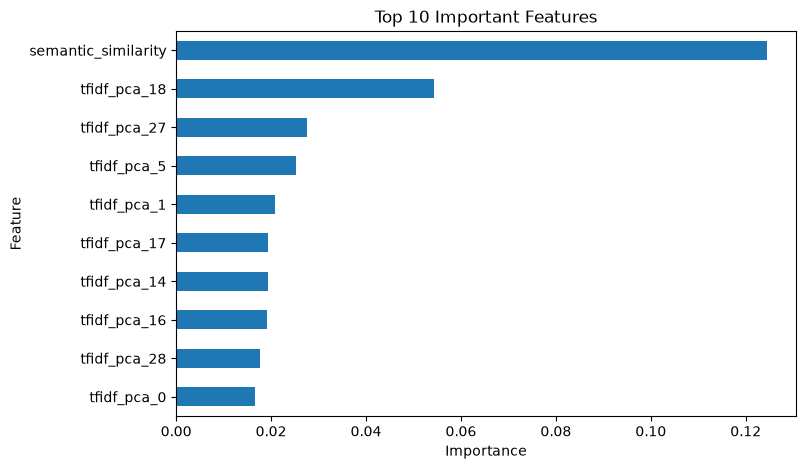

In [25]:
import matplotlib.pyplot as plt

importance.head(10)["importance"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [26]:
sensitive_columns = [
    "gender",
    "age",
    "race",
    "ethnicity",
    "sex"
]

available_sensitive = [
    col for col in sensitive_columns
    if col in df.columns
]

print("Sensitive attributes available:", available_sensitive)

if not available_sensitive:
    print("\nFairness TPR analysis cannot be computed.")
    print("Reason: the supplied dataset has no candidate demographic")
    print("attribute such as gender, age, race, or ethnicity.")
else:
    print(
        "Fairness analysis can be performed using:",
        available_sensitive
    )

Sensitive attributes available: []

Fairness TPR analysis cannot be computed.
Reason: the supplied dataset has no candidate demographic
attribute such as gender, age, race, or ethnicity.


In [27]:
output = results[
    [
        "rank",
        "predicted_score",
        "matched_score",
        "semantic_similarity",
        "experience_adequacy"
    ]
]

output.to_csv(
    "resume_screening_results.csv",
    index=False
)

print("Saved: resume_screening_results.csv")

Saved: resume_screening_results.csv


In [29]:
print("\n" + "="*60)
print("        FINAL RESUME SCREENING RESULTS")
print("="*60)

# Model performance
print("\nMODEL PERFORMANCE")
print("-"*40)
print(f"R2 Score  : {r2:.4f}")
print(f"MAE       : {mae:.4f}")
print(f"RMSE      : {rmse:.4f}")

# Top candidates
print("\nTOP 10 CANDIDATES")
print("-"*60)

top_candidates = results.head(10)

print(
    top_candidates[
        [
            "rank",
            "predicted_score",
            "matched_score",
            "semantic_similarity",
            "experience_adequacy"
        ]
    ].to_string(index=False)
)
print("\n" + "="*60)
print("        TOP TF-IDF FEATURES")
print("="*60)

feature_names = tfidf.get_feature_names_out()

tfidf_importance = np.asarray(X_tfidf.mean(axis=0)).flatten()

top_indices = np.argsort(
    tfidf_importance
)[::-1][:20]

tf_features = pd.DataFrame({
    "TF_IDF_Feature": feature_names[top_indices],
    "Importance": tfidf_importance[top_indices]
})

print(tf_features.to_string(index=False))

print("\n" + "="*60)
print("MODEL FEATURE IMPORTANCE")
print("="*60)

importance = predictor.feature_importance(
    test_data,
    silent=True
)

print(importance.head(15).to_string())


print("\n" + "="*60)
print("                    CONCLUSION")
print("="*60)


        FINAL RESUME SCREENING RESULTS

MODEL PERFORMANCE
----------------------------------------
R2 Score  : 0.6887
MAE       : 0.0704
RMSE      : 0.0928

TOP 10 CANDIDATES
------------------------------------------------------------
 rank  predicted_score  matched_score  semantic_similarity  experience_adequacy
    1         0.933392       0.850000             0.379232                  0.0
    2         0.922879       0.873333             0.502526                  1.0
    3         0.907226       0.850000             0.672710                  1.0
    4         0.904189       0.850000             0.530829                  0.0
    5         0.900842       0.926667             0.474411                  0.0
    6         0.900061       0.850000             0.497537                  0.0
    7         0.887244       0.936667             0.225043                  0.0
    8         0.884580       0.850000             0.534945                  0.0
    9         0.883572       0.893333      